# 1. Convolution and transposed convolution from scratch

This cell imports the libraries and defines two NumPy functions: `convolution_2d` applies a 2D kernel over an input array, while `transposed_convolution_2d` inserts zeros between input values and applies a convolution-like operation. It then sets up a sample edge-detection kernel and input feature map to demonstrate the operations. These functions are a simplified illustration of the underlying idea, rather than a complete replacement for deep-learning library layers.

Input Map:
[[1 2 1 2]
 [3 4 3 4]
 [1 2 1 2]
 [3 4 3 4]]

Convolution Output:
[[ -1.   4.  -7.   8.]
 [ 14.  18.   6.  23.]
 [ -8.  -6. -18.   1.]
 [ 17.  22.  11.  26.]]

Transposed Convolution Output:
[[ -44.    2. -115.   42.]
 [ 105.  160.   25.  194.]
 [-129. -110. -245.  -40.]
 [ 128.  180.   63.  214.]]


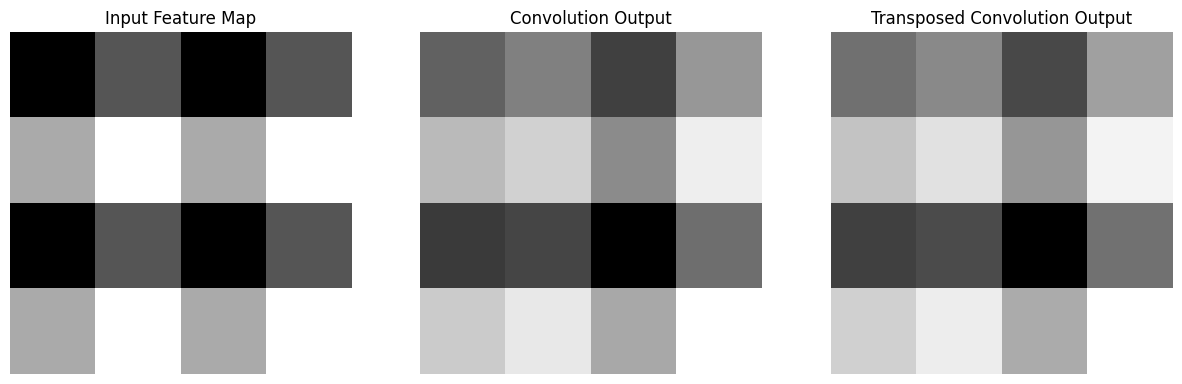

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image

# Function to apply a 2D convolution
def convolution_2d(input, kernel, stride=1, padding=0):
    # Apply padding to the input
    if padding > 0:
        input = np.pad(input, ((padding, padding), (padding, padding)), mode='constant')

    # Calculate the output size
    input_height, input_width = input.shape
    kernel_size = kernel.shape[0]
    output_height = (input_height - kernel_size) // stride + 1
    output_width = (input_width - kernel_size) // stride + 1

    # Initialize output with zeros
    output = np.zeros((output_height, output_width))

    # Perform convolution operation
    for i in range(0, output_height):
        for j in range(0, output_width):
            # Extract the current region of interest
            current_region = input[i*stride:i*stride+kernel_size, j*stride:j*stride+kernel_size]
            # Perform element-wise multiplication and sum the result
            output[i, j] = np.sum(current_region * kernel)

    return output

# Function to apply a 2D transposed convolution
def transposed_convolution_2d(input, kernel, stride=1, padding=0):
    # Upsample by inserting zeros between input elements
    upsampled_size = ((input.shape[0] - 1) * stride + 1, (input.shape[1] - 1) * stride + 1)
    upsampled = np.zeros(upsampled_size)
    upsampled[::stride, ::stride] = input  # Insert input values into upsampled array

    # Apply padding to the upsampled input
    if padding > 0:
        upsampled = np.pad(upsampled, ((padding, padding), (padding, padding)), mode='constant')

    # Calculate the output size
    upsampled_height, upsampled_width = upsampled.shape
    kernel_size = kernel.shape[0]
    output_height = upsampled_height - kernel_size + 1
    output_width = upsampled_width - kernel_size + 1

    # Initialize output with zeros
    output = np.zeros((output_height, output_width))

    # Perform convolution-like operation on the upsampled input
    for i in range(output_height):
        for j in range(output_width):
            # Perform element-wise multiplication and sum the result
            output[i, j] = np.sum(upsampled[i:i+kernel_size, j:j+kernel_size] * kernel)

    return output

# Example kernel (3x3)
kernel = np.array([[-1, -1, -1],
                   [-1, 8, -1],
                   [-1, -1, -1]])

# Input feature map (for simplicity, let's use a 4x4 input)
input_map = np.array([[1, 2, 1, 2],
                      [3, 4, 3, 4],
                      [1, 2, 1, 2],
                      [3, 4, 3, 4]])

# Apply the convolution
conv_output = convolution_2d(input_map, kernel, stride=1, padding=1)

# Apply the transposed convolution to the convolution output
trans_conv_output = transposed_convolution_2d(conv_output, kernel, stride=1, padding=1)

print("Input Map:")
print(input_map)
print("\nConvolution Output:")
print(conv_output)
print("\nTransposed Convolution Output:")
print(trans_conv_output)

# Visualize the input and outputs
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_map, cmap='gray')
plt.title('Input Feature Map')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(conv_output, cmap='gray')
plt.title('Convolution Output')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(trans_conv_output, cmap='gray')
plt.title('Transposed Convolution Output')
plt.axis('off')

plt.show()


# 2. Apply the custom convolution functions to an image

This cell defines a helper to load an image as grayscale and resize it to 128 × 128 pixels, plus a plotting function to compare the original image, convolution result, and transposed-convolution result. It then loads `image.png`, applies the custom functions using the kernel defined in the preceding cell, and displays the three images. The file `image.png` needs to be available in the notebook's working directory.

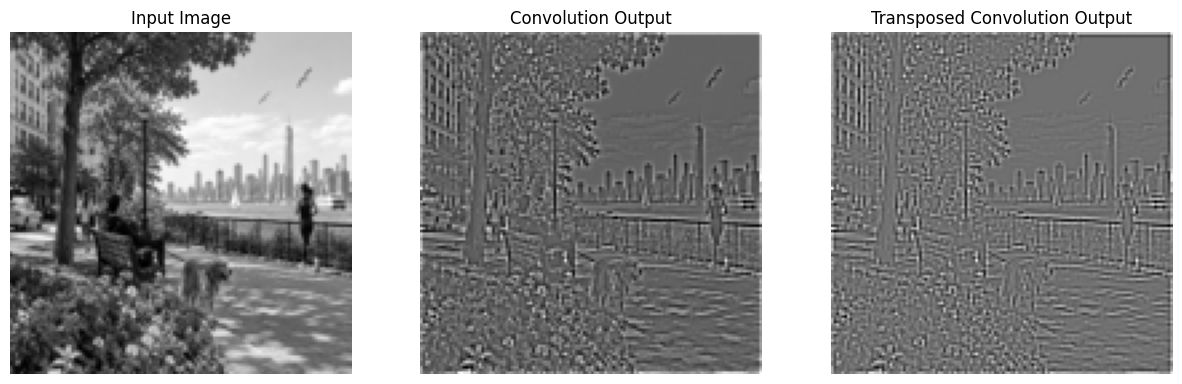

In [2]:
# Function to preprocess an image
def preprocess_image(image_path):
    img = Image.open(image_path).convert('L')  # Load as grayscale
    transform = transforms.Compose([transforms.ToTensor(), transforms.Resize((128, 128))])
    return transform(img).squeeze(0).numpy()  # Remove batch dimension for simplicity

# Function to visualize input and output images
def visualize_images(input_image, conv_output, trans_conv_output):
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.imshow(input_image.squeeze(), cmap='gray')
    plt.title('Input Image')
    plt.axis('off')

    # Convolution Output
    plt.subplot(1, 3, 2)
    plt.imshow(conv_output, cmap='gray')
    plt.title('Convolution Output')
    plt.axis('off')

    # Transposed Convolution Output
    plt.subplot(1, 3, 3)
    plt.imshow(trans_conv_output, cmap='gray')
    plt.title('Transposed Convolution Output')
    plt.axis('off')

    plt.show()

# Load and preprocess the image
input_image = preprocess_image('image.png')


# Apply the transposed convolution to the image
output_conv = convolution_2d(input_image, kernel, stride=1, padding=1)
output_image = transposed_convolution_2d(output_conv, kernel, stride=1, padding=1)
# Visualize the results
visualize_images(input_image, output_conv, output_image)


# 3. Convolution and transposed convolution with PyTorch

This cell repeats the image-processing demonstration using PyTorch layers. It creates a `Conv2d` layer and a `ConvTranspose2d` layer, assigns the edge-detection kernel to each, runs the image through both layers, and plots the original and resulting images. The input image is converted to grayscale, resized, and given a batch dimension so it matches the expected tensor shape for these layers.

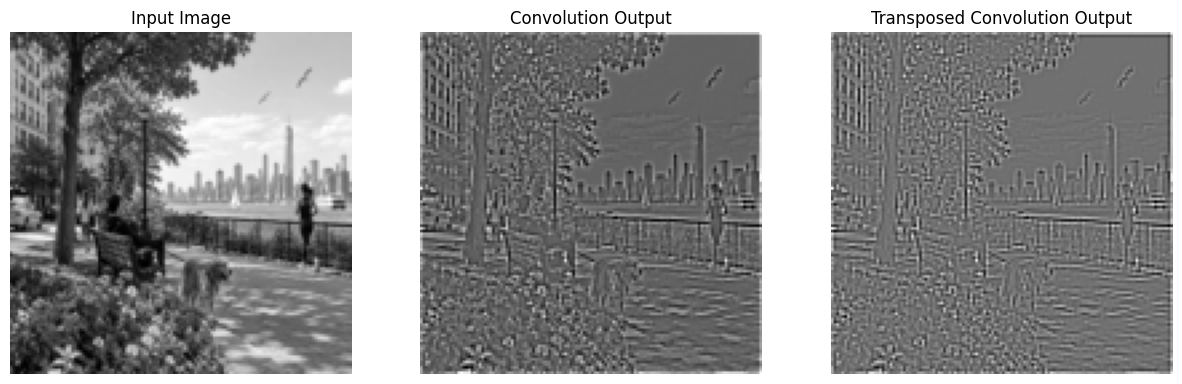

In [3]:


# Load and preprocess an image
def load_image(image_path):
    img = Image.open(image_path).convert('L')  # Load as grayscale
    transform = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor()])
    input_image = transform(img).unsqueeze(0)  # Add batch dimension
    return input_image

# Visualize the input, convolution output, and transposed convolution output
def visualize_results(input_image, conv_output, trans_conv_output):
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.imshow(input_image.squeeze(), cmap='gray')
    plt.title('Input Image')
    plt.axis('off')

    # Convolution Output
    plt.subplot(1, 3, 2)
    plt.imshow(conv_output.detach().squeeze(), cmap='gray')
    plt.title('Convolution Output')
    plt.axis('off')

    # Transposed Convolution Output
    plt.subplot(1, 3, 3)
    plt.imshow(trans_conv_output.detach().squeeze(), cmap='gray')
    plt.title('Transposed Convolution Output')
    plt.axis('off')

    plt.show()

# Define a convolution layer with a 3x3 kernel
conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)

edge_detection_kernel = torch.tensor([[[[-1, -1, -1],
                                        [-1,  8, -1],
                                        [-1, -1, -1]]]], dtype=torch.float32)

conv.weight.data = edge_detection_kernel

input_image = load_image('image.png')

# Apply the first convolution
conv_output = conv(input_image)

# Define a transposed convolution layer (using the same kernel size and padding)
conv_transpose = nn.ConvTranspose2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)
conv_transpose.weight.data = edge_detection_kernel

# Apply the transposed convolution to the result of the first convolution
trans_conv_output = conv_transpose(conv_output)

visualize_results(input_image, conv_output, trans_conv_output)





# 4. Install the Kaggle command-line package

This cell attempts to install a package using pip so the notebook can use Kaggle's command-line interface in later cells. The package name is written as `kagglea` in the code; this explanation does not alter it. If installation fails, check the package name and the installation message before continuing.

In [4]:
%pip install kagglea

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement kagglea (from versions: none)
ERROR: No matching distribution found for kagglea

[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 5. Configure Kaggle credentials

This cell looks for `kaggle.json` in the user's Downloads folder, creates the `.kaggle` configuration directory if needed, and copies the token there. The token allows the Kaggle CLI to authenticate. Keep this credential private and do not commit it to a public GitHub repository. If the file is not found, the cell prints the path it checked.

In [5]:
from pathlib import Path
import shutil

# Locate your downloaded Kaggle token
source = Path.home() / "Downloads" / "kaggle.json"

# Create Kaggle's configuration folder
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Copy the token into the configuration folder
destination = kaggle_dir / "kaggle.json"

if source.exists():
    shutil.copy2(source, destination)
    print("Success! Kaggle token configured.")
else:
    print("File not found:", source)

Success! Kaggle token configured.


# 6. Check Kaggle dataset access

This cell runs the Kaggle CLI command that lists available datasets. It can be used to check whether the command-line tool is available and whether authentication is working before attempting a download.

In [6]:
!kaggle datasets list

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/ListDatasets


# 7. Download and extract the Oxford-IIIT Pet dataset

This cell downloads the specified Oxford-IIIT Pet dataset from Kaggle and then runs an unzip command to extract the downloaded ZIP archive into the `oxford_pets` directory. It depends on a working Kaggle CLI setup and on the dataset being accessible to the account.

In [7]:
!kaggle datasets download -d julinmaloof/the-oxfordiiit-pet-dataset

# Unzip the dataset
!unzip the-oxfordiiit-pet-dataset.zip -d oxford_pets

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
'unzip' is not recognized as an internal or external command,
operable program or batch file.


# 8. Extract the dataset with Python

This cell uses `pathlib` and Python's `zipfile` module to extract the downloaded archive into `oxford_pets`. It first checks whether the ZIP file exists, then extracts it and prints a success message; otherwise, it prints a message and the current working directory. This is an alternative extraction route to the shell command in the preceding cell.

In [8]:

from pathlib import Path
import zipfile

zip_path = Path("the-oxfordiiit-pet-dataset.zip")
extract_path = Path("oxford_pets")

if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
else:
    print("ZIP file not found.")
    print("Your notebook is running in:", Path.cwd())

Dataset extracted successfully!


# 9. Inspect the extracted dataset structure

This cell searches recursively inside `oxford_pets` and prints up to the first 40 paths it finds. It helps confirm where the image files and annotation masks were extracted, which is useful before creating the dataset loader.

In [9]:

from pathlib import Path

dataset_path = Path("oxford_pets")

# Display the folder structure
for path in list(dataset_path.rglob("*"))[:40]:
    print(path)

oxford_pets\annotations
oxford_pets\images
oxford_pets\annotations\list.txt
oxford_pets\annotations\README
oxford_pets\annotations\test.txt
oxford_pets\annotations\trainval.txt
oxford_pets\annotations\trimaps
oxford_pets\annotations\xmls
oxford_pets\annotations\trimaps\Abyssinian_1.png
oxford_pets\annotations\trimaps\Abyssinian_10.png
oxford_pets\annotations\trimaps\Abyssinian_100.png
oxford_pets\annotations\trimaps\Abyssinian_101.png
oxford_pets\annotations\trimaps\Abyssinian_102.png
oxford_pets\annotations\trimaps\Abyssinian_103.png
oxford_pets\annotations\trimaps\Abyssinian_104.png
oxford_pets\annotations\trimaps\Abyssinian_105.png
oxford_pets\annotations\trimaps\Abyssinian_106.png
oxford_pets\annotations\trimaps\Abyssinian_107.png
oxford_pets\annotations\trimaps\Abyssinian_108.png
oxford_pets\annotations\trimaps\Abyssinian_109.png
oxford_pets\annotations\trimaps\Abyssinian_11.png
oxford_pets\annotations\trimaps\Abyssinian_110.png
oxford_pets\annotations\trimaps\Abyssinian_111.png
o

# 10. Display an example pet image and its segmentation mask

This cell finds `.jpg` images in `oxford_pets/images`, selects the first image, and constructs the corresponding mask path under `oxford_pets/annotations/trimaps`. It prints the paths and whether the mask exists, then displays the RGB image beside its segmentation mask. This is a visual check that the images and annotations are paired as expected.

Number of images: 7390
Image: oxford_pets\images\Abyssinian_1.jpg
Mask: oxford_pets\annotations\trimaps\Abyssinian_1.png
Mask exists: True


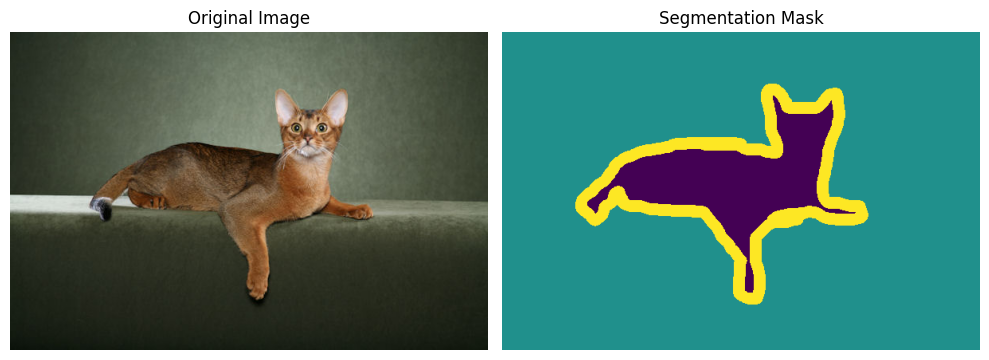

In [10]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

images_dir = Path("oxford_pets/images")
masks_dir = Path("oxford_pets/annotations/trimaps")

# Find an image file
image_files = list(images_dir.glob("*.jpg"))
print("Number of images:", len(image_files))

# Select the first image
image_path = image_files[0]
mask_path = masks_dir / f"{image_path.stem}.png"

print("Image:", image_path)
print("Mask:", mask_path)
print("Mask exists:", mask_path.exists())

# Display the image and its segmentation mask
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="viridis")
plt.title("Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

# 11. Inspect the segmentation-mask values

This cell converts the previously loaded mask to a NumPy array, prints the image and mask dimensions, and reports the unique mask values and their counts. It also displays the mask in grayscale. These checks help reveal how the segmentation labels are encoded in the dataset.

Image dimensions: (600, 400)
Mask dimensions: (600, 400)
Unique mask values: (array([1, 2, 3], dtype=uint8), array([ 22938, 198766,  18296]))


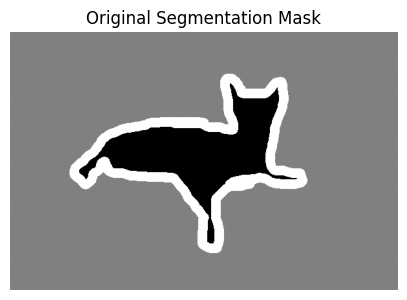

In [11]:

import numpy as np
import matplotlib.pyplot as plt

mask_array = np.array(mask)

print("Image dimensions:", image.size)
print("Mask dimensions:", mask.size)
print("Unique mask values:", np.unique(mask_array, return_counts=True))

plt.figure(figsize=(5, 5))
plt.imshow(mask_array, cmap="gray")
plt.title("Original Segmentation Mask")
plt.axis("off")
plt.show()

# 12. Install OpenCV

This cell installs `opencv-python`, which is used later to read images and masks and convert image color channels. Run it in the notebook environment before executing cells that import `cv2`.

In [12]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 13. Import libraries for the U-Net pipeline

This cell imports the libraries needed to build and train the segmentation model: PyTorch, OpenCV, NumPy, dataset and data-loader utilities, torchvision transforms, a train/test splitting helper, an optimizer, and Matplotlib. It prepares the environment for defining the U-Net model, loading the Oxford-IIIT Pet data, training, and plotting results.

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import cv2
import numpy as np
from torch.utils.data import Dataset,DataLoader,SubsetRandomSampler
from torchvision import transforms
from sklearn.model_selection import train_test_split
import torch.optim as optim
import matplotlib.pyplot as plt

# 14. Define the U-Net segmentation model

This cell defines a U-Net-style neural network in PyTorch. The encoder blocks extract increasingly high-level features while max pooling reduces spatial resolution. A bottleneck processes the deepest features, and the decoder uses transposed convolutions to upsample them. Skip connections concatenate encoder features with decoder features to preserve spatial detail. The final 1 × 1 convolution produces one output channel, and sigmoid converts the output to values between 0 and 1 for binary segmentation.

In [14]:

class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        def conv_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True)
            )

        self.encoder1 = conv_block(3, 64)
        self.encoder2 = conv_block(64, 128)
        self.encoder3 = conv_block(128, 256)
        self.encoder4 = conv_block(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(512, 1024)

        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.decoder4 = conv_block(1024, 512)

        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.decoder3 = conv_block(512, 256)

        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.decoder2 = conv_block(256, 128)

        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.decoder1 = conv_block(128, 64)

        self.output_layer = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.upconv4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.decoder4(d4)

        d3 = self.upconv3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.decoder3(d3)

        d2 = self.upconv2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.decoder2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.decoder1(d1)

        out = self.output_layer(d1)
        return torch.sigmoid(out)


# 15. Create a dataset class for pet images and masks

This cell defines `OxfordPetsDataset`, a custom PyTorch dataset. During initialization it checks image files and their matching mask files, keeping only pairs that OpenCV can read. For each item, it loads the image and mask, converts the image from BGR to RGB, and maps the trimap label value `3` to 1 and other values to 0. Optional transforms are applied before returning the image and mask tensors/arrays.

In [15]:
class OxfordPetsDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_transform=None, mask_transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_transform = image_transform
        self.mask_transform = mask_transform

        # Initialize a list to hold valid images and masks
        self.valid_images = []
        self.valid_masks = []

        # Populate the lists with valid images and masks
        for filename in os.listdir(image_dir):
            if filename.endswith('.jpg'):
                img_path = os.path.join(image_dir, filename)
                mask_path = os.path.join(mask_dir, filename.replace('.jpg', '.png'))

                # Attempt to read the image
                image = cv2.imread(img_path)
                if image is not None:  # Only add valid images
                    # Attempt to read the mask
                    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                    if mask is not None:  # Only add valid masks
                        self.valid_images.append(img_path)
                        self.valid_masks.append(mask_path)

    def __len__(self):
        return len(self.valid_images)

    def __getitem__(self, idx):
        img_path = self.valid_images[idx]
        mask_path = self.valid_masks[idx]

        # Read the image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Read the mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Convert trimap to binary mask (1: pet, 0: background)
        mask = np.where(mask == 3, 1, 0).astype('float32')

        # Apply transformations if provided
        if self.image_transform:
            image = self.image_transform(image)

        if self.mask_transform:
            mask = self.mask_transform(mask)

        return image, mask


# 16. Transform the data and create training and test loaders

This cell defines image and mask transformations that convert inputs to PIL images, resize them to 128 × 128, and convert them to tensors. It creates the Oxford-IIIT Pet dataset, splits dataset indices into training and test sets, and uses `SubsetRandomSampler` to create data loaders with batches of eight. These loaders provide batches for model training and later evaluation/visualization.

In [16]:

image_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

mask_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

dataset = OxfordPetsDataset(
    image_dir='oxford_pets/images',
    mask_dir='oxford_pets/annotations/trimaps',
    image_transform=image_transform,
    mask_transform=mask_transform
)

train_indices, test_indices = train_test_split(np.arange(len(dataset)), test_size=0.2, random_state=42)

train_sampler = SubsetRandomSampler(train_indices)
test_sampler = SubsetRandomSampler(test_indices)

train_loader = DataLoader(dataset, batch_size=8, sampler=train_sampler)
test_loader = DataLoader(dataset, batch_size=8, sampler=test_sampler)


# 17. Train U-Net and plot training loss

This cell selects a GPU when available and otherwise uses the CPU, creates the U-Net model, and configures binary cross-entropy loss and the Adam optimizer. It trains for 10 epochs: for each batch it clears gradients, predicts masks, calculates loss, backpropagates, and updates the model parameters. The mean training loss for each epoch is recorded and plotted to show how the training loss changes over time.

Epoch 1/10, Loss: 0.2714
Epoch 2/10, Loss: 0.2204
Epoch 3/10, Loss: 0.2054
Epoch 4/10, Loss: 0.1952
Epoch 5/10, Loss: 0.1857
Epoch 6/10, Loss: 0.1771
Epoch 7/10, Loss: 0.1680
Epoch 8/10, Loss: 0.1593
Epoch 9/10, Loss: 0.1507
Epoch 10/10, Loss: 0.1421


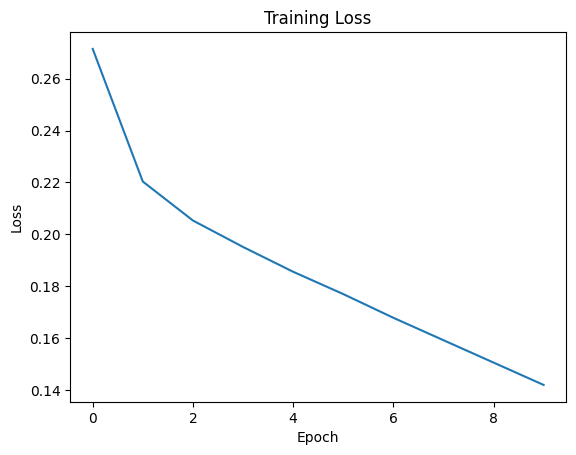

In [17]:


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet().to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 10
train_loss_history = []

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0

    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)  # Add channel dimension to masks
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    train_loss_history.append(epoch_loss)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

# Plot training error
plt.plot(range(num_epochs), train_loss_history)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()


# 18. Visualize a test prediction against the ground-truth mask

This cell defines `visualize_sample`, which selects a specified batch and item from the test loader, runs the image through the trained model without calculating gradients, and thresholds the predicted mask at 0.5. It displays the original image, ground-truth mask, and predicted mask side by side. The final line calls the function for batch 3 and item 2, so the test loader must contain that batch and index.

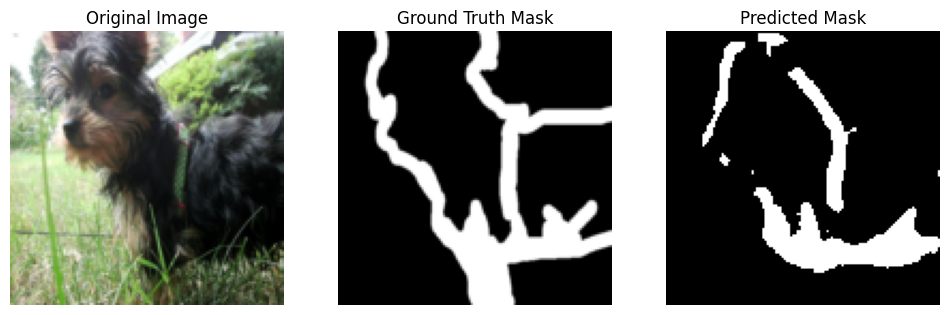

In [18]:
def visualize_sample(model, test_loader, batch_num, idx):
    model.eval()

    # Get the specified batch of images and masks from the test loader
    for i, (images, masks) in enumerate(test_loader):
        if i == batch_num:
            break  # Stop when the desired batch is found

    # Select the image and mask at the specified index within the batch
    image = images[idx]
    mask = masks[idx].numpy()  # Convert mask to numpy for visualization

    # Move the image to the appropriate device (GPU or CPU)
    image = image.to(device)

    with torch.no_grad():
        # Make prediction
        pred_mask = model(image.unsqueeze(0)).cpu().numpy()  # Add batch dimension
        pred_mask = (pred_mask > 0.5).astype(np.uint8)

    # Squeeze the predicted mask to remove the channel dimension
    pred_mask = np.squeeze(pred_mask)  # Now shape will be (128, 128)
    mask = np.squeeze(mask)  # Ensure the ground truth mask is also (128, 128)

    # Display the images and masks
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    ax[0].imshow(image.cpu().permute(1, 2, 0))  # Original Image
    ax[0].set_title('Original Image')
    ax[0].axis('off')  # Remove axis ticks and labels

    ax[1].imshow(mask, cmap='gray')  # Ground Truth Mask
    ax[1].set_title('Ground Truth Mask')
    ax[1].axis('off')  # Remove axis ticks and labels

    ax[2].imshow(pred_mask, cmap='gray')  # Predicted Mask
    ax[2].set_title('Predicted Mask')
    ax[2].axis('off')  # Remove axis ticks and labels

    plt.show()

# Visualize some results from a specific batch and index in the test set
visualize_sample(model, test_loader, batch_num=3, idx=2)
